In [64]:
# Import dependencies
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("All dependencies imported successfully.")


All dependencies imported successfully.


In [65]:
# Open the CSV file and read it into a DataFrame
main_df = pd.read_csv('data/election_data.csv')

main_df.head()

,year,candidate,political_party,electoral_votes,popular_votes,popular_percentage
0,1824,John Quincy Adams,No Party 1,84,108740,30.9
1,1824,Andrew Jackson,No Party 2,99,153544,41.3
2,1824,Henry Clay,No Party 3,37,47531,13.0
3,1824,William H. Crawford,No Party 4,41,40856,11.2
4,1828,Andrew Jackson,Democratic,178,647286,56.0


In [86]:
# Define year for analaysis
year = 2016

# Create a dataframe filtered by a specific year (e.g., 2020)
df = main_df[main_df['year'] == year]
print("Year selected successfully.")

# Define the list of candidates from the filtered DataFrame
candidates = df['candidate'].unique()

# Define the size of the candidates list
size = len(candidates)

print(f"Candidates extracted successfully: {size}")
df.head()

Year selected successfully.
Candidates extracted successfully: 2


,year,candidate,political_party,electoral_votes,popular_votes,popular_percentage
137,2016,Donald Trump,Republican,304,62984828,46.1
138,2016,Hillary Clinton,Democratic,227,65853514,48.2


In [87]:
# Create lists of data for the inner and outer pie charts
# Retain the order of the candidates in the inner and outer pie charts

inner_data = df['popular_votes'].values
outer_data = df['electoral_votes'].values

# Print the lists of data for verification
print("Inner data (popular votes):", inner_data)
print("Outer data (electoral votes):", outer_data)


Inner data (popular votes): [62984828 65853514]
Outer data (electoral votes): [304 227]


In [88]:
# Normalize the data for the pie charts
inner_data_normalized = inner_data / np.sum(inner_data)
outer_data_normalized = outer_data / np.sum(outer_data)

In [89]:
# List all the political parties in the dataset
parties = main_df['political_party'].unique()

print("Political parties extracted successfully:", parties)

Political parties extracted successfully: <StringArray>
[                   'No Party 1',                    'No Party 2',
                    'No Party 3',                    'No Party 4',
                    'Democratic',           'National Republican',
                  'Anti-Masonic',                    'Nullifiers',
                             nan,                          'Whig',
                  'Anti-Jackson',                       'Liberty',
                     'Free Soil',                    'Republican',
                      'American',           'Southern Democratic',
          'Constitutional Union', 'Democratic/Liberal Republican',
        'Independent-Democratic',                     'Greenback',
                   'Prohibition',                       'Peoples',
                     'Socialist',                   'Progressive',
                 'States Rights',               'not a candidate',
          'American Independent',                   'Independent',
      

In [90]:
# Define the party colors for the candidates
party_colors = {
    'No Party 1': '#1f77b4',  # Blue
    'No Party 2': '#ff7f0e',  # Orange
    'No Party 3': '#2ca02c',  # Green
    'No Party 4': '#d62728',  # Red
    'Democratic': '#1f77b4',  # Blue
    'Republican': '#d62728',  # Red
    'National Republican': '#ff7f0e',  # Orange
    'Anti-Masonic': '#2ca02c',  # Green
    'Nullifiers': '#d62728',  # Red
    np.nan: '#9467bd',  # Purple
    'Whig': '#8c564b',  # Brown
    'Anti-Jackson': '#e377c2',  # Pink
    'Liberty': '#7f7f7f',  # Gray
    'Anti-Grant': '#bcbd22',  # Olive
    'Free Soil': '#17becf',  # Cyan
    'States Rights': '#e377c2',  # Pink
    'not a candidate': '#7f7f7f',  # Gray
    'American Independent': '#e377c2',  # Pink
    'Independent': '#1f77b4',  # Blue
    'Reform': '#2ca02c',  # Green
    'Green': '#2ca02c'  # Green
}

In [91]:
# create a function to get the color for each candidate based on their political party
def get_candidate_color(party):
    return party_colors.get(party, '#7f7f7f')  # Default to gray if party not found


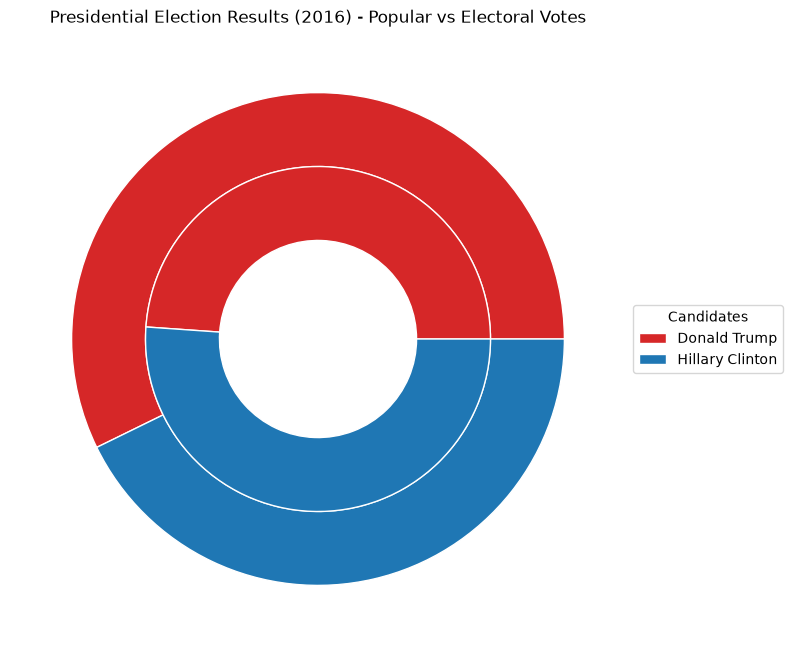

In [92]:

fig, ax = plt.subplots(figsize=(8, 8))

# Outer Chart
outer = ax.pie(outer_data_normalized, radius=1, colors=[get_candidate_color(party) for party in df['political_party']],
               wedgeprops=dict(width=0.3, edgecolor='w'))

# Inner Chart
inner = ax.pie(inner_data_normalized, radius=0.7, colors=[get_candidate_color(party) for party in df['political_party']],
               wedgeprops=dict(width=0.3, edgecolor='w'))

# Adding a Legend
ax.legend(candidates, title="Candidates", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.title(f"Presidential Election Results ({year}) - Popular vs Electoral Votes")
plt.show()